<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/08-visualization/03_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 8: Solutions

Try the exercises first. The notes after each solution explain the choices that make each chart honest and readable, and the Matplotlib details that are easy to get wrong.

In [1]:
# Setup: run this cell once before you start.
# It sets up the course plotting style and defines the check functions.
# Checks close the figures they inspect; after a PASS they draw one example
# with your function so you can see it.

import copy
import math
import inspect
import tempfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
from io import StringIO


import matplotlib.colors as mcolors

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()


class Raises:
    """Marks a test case where the code is expected to raise an error."""
    def __init__(self, exc):
        self.exc = exc

    def __repr__(self):
        return f"{self.exc.__name__} to be raised"


def _same(a, b, tol=1e-6):
    if isinstance(a, (pd.DataFrame, pd.Series)) or isinstance(b, (pd.DataFrame, pd.Series)):
        if type(a) is not type(b):
            return False
        options = dict(check_dtype=False, check_exact=False, rtol=tol, atol=tol, check_index_type=False)
        try:
            if isinstance(a, pd.DataFrame):
                pd.testing.assert_frame_equal(a, b, check_column_type=False, **options)
            else:
                pd.testing.assert_series_equal(a, b, **options)
            return True
        except AssertionError:
            return False
    if isinstance(a, np.ndarray) or isinstance(b, np.ndarray):
        try:
            a_arr, b_arr = np.asarray(a), np.asarray(b)
        except Exception:
            return False
        if a_arr.shape != b_arr.shape:
            return False
        if a_arr.dtype.kind in "fc" or b_arr.dtype.kind in "fc":
            return bool(np.allclose(a_arr, b_arr, rtol=tol, atol=tol))
        return bool(np.array_equal(a_arr, b_arr))
    if isinstance(a, (float, np.floating)) or isinstance(b, (float, np.floating)):
        if not isinstance(a, (int, float, np.number)) or not isinstance(b, (int, float, np.number)):
            return False
        if math.isnan(a) or math.isnan(b):
            return False
        return math.isclose(a, b, rel_tol=tol, abs_tol=tol)
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(_same(x, y) for x, y in zip(a, b))
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(_same(a[k], b[k]) for k in a)
    return a == b


def _short(x, limit=90):
    if isinstance(x, (pd.DataFrame, pd.Series)):
        lines = (x.to_string(max_rows=6, max_cols=6) if isinstance(x, pd.DataFrame) else x.to_string(max_rows=6)).splitlines()
        return f"{type(x).__name__} shape={x.shape}\n          " + "\n          ".join(lines[:8])
    if isinstance(x, np.ndarray):
        body = np.array2string(x, precision=4, threshold=12, edgeitems=3, separator=", ")
        text = f"array(shape={x.shape}, dtype={x.dtype}, {' '.join(body.split())})"
    elif isinstance(x, tuple) and any(isinstance(i, np.ndarray) for i in x):
        text = "(" + ", ".join(_short(i, limit) for i in x) + ")"
        return text
    else:
        text = repr(x)
    if isinstance(x, (pd.DataFrame, pd.Series)):
        return text
    return text if len(text) <= limit else text[:limit - 3] + "..."


def _scenarios(name, cases):
    for description, scenario, expected, hint in cases:
        try:
            result = scenario()
            plt.close("all")
        except Exception as e:
            plt.close("all")
            if isinstance(expected, Raises) and isinstance(e, expected.exc):
                continue
            print(f"FAIL  {name}: {description}")
            print(f"      raised {type(e).__name__}: {e}")
            if isinstance(expected, Raises):
                print(f"      expected {expected!r}")
            else:
                print(f"      expected: {_short(expected)}")
            if hint:
                print(f"      hint: {hint}")
            return False
        if isinstance(expected, Raises):
            print(f"FAIL  {name}: {description}")
            print(f"      expected {expected!r}, but nothing was raised")
            if hint:
                print(f"      hint: {hint}")
            return False
        if not _same(result, expected):
            print(f"FAIL  {name}: {description}")
            print(f"      expected: {_short(expected)}")
            print(f"      got:      {_short(result)}")
            if hint:
                print(f"      hint: {hint}")
            return False
    print(f"PASS  all {len(cases)} tests passed for {name}")
    return True


def _hex(colour):
    return mcolors.to_hex(colour).lower()


def _title(ax):
    """The axes title, wherever it was placed (the house style puts titles on the left)."""
    return next((ax.get_title(loc) for loc in ("left", "center", "right") if ax.get_title(loc)), "")


def _data_lines(ax):
    """Lines that carry data (skips axhline/axvline reference lines)."""
    return [l for l in ax.get_lines() if len(np.atleast_1d(l.get_xdata())) > 2]


def _sample_penguins():
    rng = np.random.default_rng(3)
    rows = []
    for sp, (bl, mass) in {"Adelie": (39, 3700), "Chinstrap": (49, 3730), "Gentoo": (47, 5080)}.items():
        for _ in range(30):
            rows.append({"species": sp, "bill_length_mm": rng.normal(bl, 2.5),
                         "body_mass_g": rng.normal(mass, 350), "flipper_length_mm": rng.normal(200, 8)})
    return pd.DataFrame(rows)


# ---- checks ----

def check_line_chart(f):
    x = np.arange(10)
    y = x ** 2

    def info():
        fig, ax = f(x, y, "Squares grow fast", "n", "n squared")
        lines = _data_lines(ax)
        return (len(lines), _title(ax), ax.get_xlabel(), ax.get_ylabel())

    def data():
        fig, ax = f(x, y, "t", "x", "y")
        line = _data_lines(ax)[0]
        return (np.asarray(line.get_xdata()), np.asarray(line.get_ydata()))

    def style():
        fig, ax = f(x, y, "t", "x", "y")
        return (_hex(_data_lines(ax)[0].get_color()), ax.get_legend() is None)

    passed = _scenarios("line_chart", [
        ("returns (fig, ax) with one line, a title and axis labels", info,
         (1, "Squares grow fast", "n", "n squared"), "fig, ax = plt.subplots(); ax.plot(...); ax.set_title(...); return fig, ax"),
        ("plots the data given", data, (x, y), None),
        ("first palette colour, no legend for a single series", style, (PALETTE[0], True),
         "one series doesn't need a legend: the title says what it is"),
    ])
    if passed:
        f(x, y, "Example: squares grow fast", "n", "n squared")


def check_histogram(f):
    values = np.array([1.0, 2.0, 2.5, 3.0, np.nan, 3.5, 4.0, 8.0, np.nan])

    def bars():
        fig, ax = f(values, 5, "value")
        heights = [p.get_height() for p in ax.patches]
        return (len(ax.patches), sum(heights))

    def labels():
        fig, ax = f(values, 5, "Body mass (g)")
        return (ax.get_xlabel(), ax.get_ylabel())

    passed = _scenarios("histogram", [
        ("missing values are dropped, every other value counted once", bars, (5, 7),
         "np.histogram can't work out a range when there are NaNs: drop them first"),
        ("axis labels", labels, ("Body mass (g)", "Count"), "set the y label to 'Count'"),
    ])
    if passed:
        f(np.random.default_rng(0).normal(4200, 800, 300), 20, "Body mass (g)")


def check_sorted_barh(f):
    labels = ["apples", "bananas", "cherries", "dates"]
    values = [30.0, 10.0, 20.0, 5.0]

    def order():
        fig, ax = f(labels, values, "Mean body mass (g)")
        bars = sorted(ax.patches, key=lambda p: p.get_y(), reverse=True)    # top bar first
        return [round(b.get_width()) for b in bars]

    def tick_labels():
        fig, ax = f(labels, values, "Mean body mass (g)")
        ticks = sorted(zip(ax.get_yticks(), [t.get_text() for t in ax.get_yticklabels()]), reverse=True)
        return [text for _, text in ticks]

    def honest():
        fig, ax = f(labels, values, "Mean body mass (g)")
        colours = {_hex(p.get_facecolor()) for p in ax.patches}
        return (ax.get_xlim()[0], len(colours), len(ax.texts))

    passed = _scenarios("sorted_barh", [
        ("largest bar at the top", order, [30, 20, 10, 5],
         "sort ascending before calling barh: barh draws the first bar at the bottom"),
        ("labels move with their bars", tick_labels, ["apples", "cherries", "bananas", "dates"],
         "reorder the labels with the same positions as the values (np.argsort), don't sort them separately"),
        ("starts at zero, one colour, a value label per bar", honest, (0.0, 1, 4),
         "ax.set_xlim(left=0); one colour for one measure; ax.text(...) at each bar end"),
    ])
    if passed:
        f(["Adelie", "Gentoo", "Chinstrap"], [3701.0, 5076.0, 3733.0], "Mean body mass (g)")


def check_save_figure(f):
    def run(formats):
        fig, ax = plt.subplots()
        ax.plot([1, 2, 3])
        folder = Path(tempfile.mkdtemp()) / "reports" / "figs"
        paths = f(fig, folder / "chart", formats)
        return fig, [Path(p) for p in paths]

    def png():
        fig, paths = run(("png",))
        return (len(paths), paths[0].suffix, paths[0].read_bytes()[:8] == b"\x89PNG\r\n\x1a\n")

    def closed():
        fig, paths = run(("png",))
        return plt.fignum_exists(fig.number)

    _scenarios("save_figure", [
        ("creates folders and a real PNG", png, (1, ".png", True), "path.parent.mkdir(parents=True, exist_ok=True)"),
        ("one file per format", lambda: sorted(p.suffix for p in run(("png", "svg"))[1]), [".png", ".svg"],
         "add the suffix with path.with_suffix('.' + fmt)"),
        ("closes the figure afterwards", closed, False, "plt.close(fig)"),
    ])


def check_scatter_by_group(f):
    df = _sample_penguins()
    order = ["Adelie", "Chinstrap", "Gentoo"]

    def colours(data):
        fig, ax = f(data, "bill_length_mm", "body_mass_g", "species", order)
        legend = ax.get_legend()
        names = [t.get_text() for t in legend.get_texts()] if legend else []
        return {name: _hex(c.get_facecolor()[0]) for name, c in zip(names, ax.collections)}

    def markers():
        fig, ax = f(df, "bill_length_mm", "body_mass_g", "species", order)
        return len({tuple(np.round(c.get_paths()[0].vertices.ravel()[:8], 3)) for c in ax.collections})

    def labels():
        fig, ax = f(df, "bill_length_mm", "body_mass_g", "species", order)
        return (ax.get_xlabel(), ax.get_ylabel(), len(ax.collections))

    passed = _scenarios("scatter_by_group", [
        ("one scatter per group, colours in order, with a legend", lambda: colours(df),
         {"Adelie": PALETTE[0], "Chinstrap": PALETTE[1], "Gentoo": PALETTE[2]},
         "loop over `order`, use PALETTE[i] for order[i], and pass label=group_name"),
        ("colour follows the group, not its position", lambda: colours(df[df["species"] != "Adelie"]),
         {"Chinstrap": PALETTE[1], "Gentoo": PALETTE[2]},
         "pick each group's colour from its position in `order`, and skip groups with no rows"),
        ("each group has its own marker shape", markers, 3, "colour shouldn't be the only way to tell groups apart"),
        ("axis labels and three groups", labels, ("bill_length_mm", "body_mass_g", 3), None),
    ])
    if passed:
        f(df, "bill_length_mm", "body_mass_g", "species", order)


def check_small_multiples(f):
    df = _sample_penguins()
    order = ["Adelie", "Chinstrap", "Gentoo"]

    def layout():
        fig = f(df, "body_mass_g", "species", order)
        return len(fig.axes)

    def shared():
        fig = f(df, "body_mass_g", "species", order)
        a, b = fig.axes[0], fig.axes[-1]
        return (a.get_xlim() == b.get_xlim(), a.get_ylim() == b.get_ylim())

    def same_bins():
        fig = f(df, "body_mass_g", "species", order)
        edges = [tuple(np.round(sorted({p.get_x() for p in ax.patches}), 6)) for ax in fig.axes]
        return len(set(edges)) == 1

    def colours():
        fig = f(df, "body_mass_g", "species", order)
        return [_hex(ax.patches[0].get_facecolor()) for ax in fig.axes]

    passed = _scenarios("small_multiples", [
        ("one panel per group", layout, 3, None),
        ("panels share both axes", shared, (True, True), "plt.subplots(n, 1, sharex=True, sharey=True)"),
        ("every panel uses the same bin edges", same_bins, True, "compute bins once with np.linspace over the whole column"),
        ("each panel in its group's colour", colours, PALETTE[:3], None),
    ])
    if passed:
        f(df, "body_mass_g", "species", order)


def check_learning_curves(f):
    epochs = np.arange(1, 21)
    train = 1.0 / epochs
    val = 0.6 / np.sqrt(epochs) + 0.004 * (epochs - 8) ** 2 / 10
    history = pd.DataFrame({"epoch": epochs, "train_loss": train, "val_loss": val})
    best_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])

    def lines():
        fig, ax = f(history)
        named = {l.get_label(): l for l in _data_lines(ax)}
        return sorted(named)

    def best_marker():
        fig, ax = f(history)
        vertical = [l for l in ax.get_lines() if len(set(np.atleast_1d(l.get_xdata()))) == 1]
        return float(np.atleast_1d(vertical[0].get_xdata())[0]) if vertical else None

    def labels():
        fig, ax = f(history)
        return (ax.get_xlabel(), ax.get_ylabel(), ax.get_legend() is not None)

    passed = _scenarios("learning_curves", [
        ("a train line and a validation line", lines, ["train", "validation"], "label='train' and label='validation'"),
        ("a vertical line at the best validation epoch", best_marker, float(best_epoch),
         "ax.axvline(epoch_with_lowest_val_loss)"),
        ("labels and a legend", labels, ("Epoch", "Loss", True), None),
    ])
    if passed:
        f(history)


def check_confusion_heatmap(f):
    cm = np.array([[38, 0, 0], [2, 15, 0], [0, 0, 31]])
    labels = ["Adelie", "Chinstrap", "Gentoo"]

    def image():
        fig, ax = f(cm, labels)
        img = ax.get_images()[0]
        return (np.asarray(img.get_array()), img.get_cmap().name)

    def numbers():
        fig, ax = f(cm, labels)
        return sorted(int(t.get_text()) for t in ax.texts)

    def text_colours():
        fig, ax = f(cm, labels)
        by_pos = {(round(t.get_position()[1]), round(t.get_position()[0])): _hex(t.get_color()) for t in ax.texts}
        return (by_pos[(0, 0)], by_pos[(1, 0)])

    def ticks():
        fig, ax = f(cm, labels)
        return ([t.get_text() for t in ax.get_xticklabels()], [t.get_text() for t in ax.get_yticklabels()],
                ax.get_xlabel(), ax.get_ylabel())

    passed = _scenarios("confusion_heatmap", [
        ("the matrix as an image, with the sequential colour scale", image, (cm, "course_blues"),
         "ax.imshow(cm, cmap=SEQUENTIAL): counts are a magnitude"),
        ("every count written in its cell", numbers, sorted(cm.ravel().tolist()), None),
        ("white text on dark cells, ink on light ones", text_colours, ("#ffffff", INK),
         "use white when the count is above half the maximum, INK otherwise"),
        ("class names on both axes", ticks, (labels, labels, "Predicted", "True"), None),
    ])
    if passed:
        f(cm, labels)


def check_indexed_chart(f):
    idx = pd.date_range("2025-01-01", periods=6, freq="MS")
    df = pd.DataFrame({"visits": [1000, 1100, 1050, 1200, 1300, 1400], "revenue": [20.0, 25, 24, 30, 36, 44]}, index=idx)

    def one_axis():
        fig, ax = f(df)
        return len(fig.axes)

    def starts():
        fig, ax = f(df)
        return sorted((l.get_label(), round(float(np.asarray(l.get_ydata())[0]), 6), round(float(np.asarray(l.get_ydata())[-1]), 6))
                      for l in _data_lines(ax))

    def reference():
        fig, ax = f(df)
        flat = [l for l in ax.get_lines() if len(set(np.round(np.atleast_1d(l.get_ydata()).astype(float), 9))) == 1]
        return (bool(flat) and float(np.atleast_1d(flat[0].get_ydata())[0]) == 100.0, "100" in ax.get_ylabel())

    passed = _scenarios("indexed_chart", [
        ("one axes only: no second y-axis", one_axis, 1, "don't use ax.twinx(): index both series instead"),
        ("each series starts at 100", starts, [("revenue", 100.0, 220.0), ("visits", 100.0, 140.0)],
         "divide each column by its first value and multiply by 100"),
        ("a reference line at 100, and the y label says so", reference, (True, True),
         "ax.axhline(100, ...) and a y label like 'Index (first month = 100)'"),
    ])
    if passed:
        f(df)


def check_correlation_heatmap(f):
    rng = np.random.default_rng(4)
    a = rng.normal(size=200)
    df = pd.DataFrame({"a": a, "b": 0.8 * a + rng.normal(0, 0.6, 200), "c": rng.normal(size=200), "d": -a + rng.normal(0, 0.3, 200)})

    def image():
        fig, ax = f(df)
        img = ax.get_images()[0]
        return (np.asarray(img.get_array()), img.get_cmap().name, img.get_clim())

    def labels():
        fig, ax = f(df)
        return ([t.get_text() for t in ax.get_xticklabels()], [t.get_text() for t in ax.get_yticklabels()], len(ax.texts))

    passed = _scenarios("correlation_heatmap", [
        ("diverging colours, fixed from -1 to 1", image, (df.corr().to_numpy(), "course_diverging", (-1.0, 1.0)),
         "ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1): without vmin/vmax a weak correlation can look strong"),
        ("column names on both axes, a number in every cell", labels, (list(df.columns), list(df.columns), 16), None),
    ])
    if passed:
        f(df)


def check_decision_regions(f):
    rng = np.random.default_rng(5)
    X = np.vstack([rng.normal([0, 0], 0.7, size=(40, 2)), rng.normal([3, 3], 0.7, size=(40, 2))])
    y = np.repeat([0, 1], 40)
    calls = []

    def predict(points):
        calls.append(np.asarray(points).shape)
        return (np.asarray(points).sum(axis=1) > 3).astype(int)

    def vectorized():
        calls.clear()
        f(predict, X, y, ["low", "high"], resolution=50)
        return calls

    def covers():
        fig, ax = f(predict, X, y, ["low", "high"], resolution=50)
        x0, x1 = ax.get_xlim()
        y0, y1 = ax.get_ylim()
        return (x0 < X[:, 0].min(), x1 > X[:, 0].max(), y0 < X[:, 1].min(), y1 > X[:, 1].max())

    def layers():
        fig, ax = f(predict, X, y, ["low", "high"], resolution=50)
        legend = ax.get_legend()
        return (len(ax.collections) >= 3, sorted(t.get_text() for t in legend.get_texts()) if legend else None)

    passed = _scenarios("decision_regions", [
        ("predict is called once, on the whole grid", vectorized, [(2500, 2)],
         "build the grid with np.meshgrid, stack it into an (n, 2) array, and predict everything in one call"),
        ("the grid extends past the data", covers, (True, True, True, True), "pad the range on every side"),
        ("filled regions plus one scatter per class, with a legend", layers, (True, ["high", "low"]),
         "ax.contourf for the regions, then ax.scatter for each class with label=labels[k]"),
    ])
    if passed:
        f(predict, X, y, ["low", "high"])


def check_rolling_band(f):
    idx = pd.date_range("2025-01-01", periods=120, freq="D")
    series = pd.Series(np.sin(np.arange(120) / 9) * 10 + np.random.default_rng(6).normal(0, 2, 120) + 50, index=idx)
    expected_mean = series.rolling(14, center=True).mean().to_numpy()

    def lines():
        fig, ax = f(series, 14)
        data = _data_lines(ax)
        alphas = sorted((l.get_alpha() if l.get_alpha() is not None else 1.0) for l in data)
        return (len(data), alphas[0] < 1.0)

    def mean_line():
        fig, ax = f(series, 14)
        for l in _data_lines(ax):
            yd = np.asarray(l.get_ydata(), dtype=float)
            if np.isnan(yd).any():
                return bool(np.allclose(yd, expected_mean, equal_nan=True))
        return "no line with the rolling mean (it should start and end with NaN)"

    def band():
        fig, ax = f(series, 14)
        return any(type(c).__name__ in ("PolyCollection", "FillBetweenPolyCollection") for c in ax.collections)

    passed = _scenarios("rolling_band", [
        ("a faint raw line and a solid average line", lines, (2, True), "draw the raw data with alpha around 0.3"),
        ("the average is a centred rolling mean", mean_line, True, "series.rolling(window, center=True).mean()"),
        ("a shaded band for mean ± one standard deviation", band, True, "ax.fill_between(index, mean - std, mean + std, alpha=0.15)"),
    ])
    if passed:
        f(series, 14)


print("Setup done. Checks are ready.")

Setup done. Checks are ready.


## Easy

### Exercise 1: `line_chart`

In [2]:
def line_chart(x, y, title: str, xlabel: str, ylabel: str):
    fig, ax = plt.subplots()
    ax.plot(x, y, color=PALETTE[0])
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return fig, ax

PASS  all 3 tests passed for line_chart


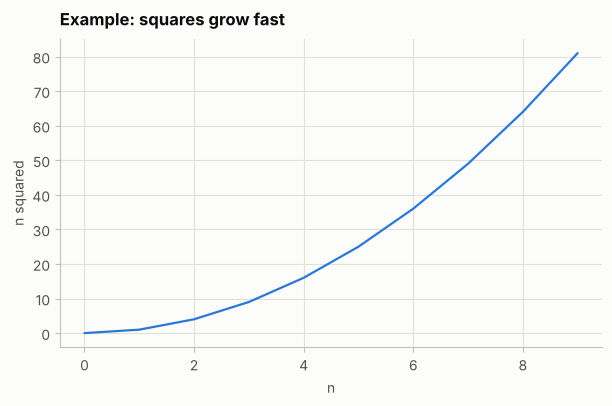

In [3]:
check_line_chart(line_chart)

Returning `(fig, ax)` instead of showing the chart makes the function reusable: the caller can add more to the axes, save the figure, put it in a report, or test it, which is exactly what the checks do.

The colour is set explicitly to `PALETTE[0]`. With the house style it would be the default anyway, but being explicit means the chart looks the same even if someone runs it without the style.

No legend: with one line, a legend box just repeats the title. Legends earn their place once there are two or more series.

### Exercise 2: `histogram`

In [4]:
def histogram(values, bins: int, xlabel: str):
    clean = np.asarray(values, dtype=float)
    clean = clean[~np.isnan(clean)]
    fig, ax = plt.subplots()
    ax.hist(clean, bins=bins, color=PALETTE[0], edgecolor=SURFACE, linewidth=1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")
    return fig, ax

PASS  all 2 tests passed for histogram


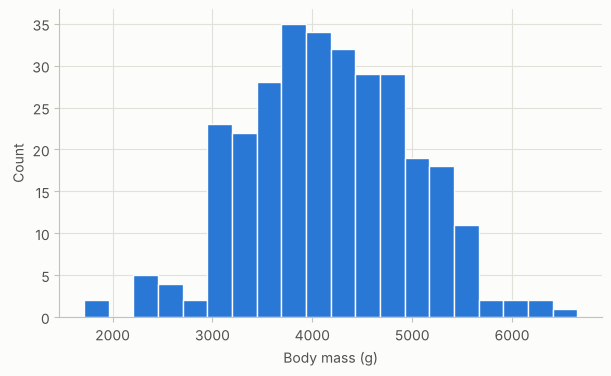

In [5]:
check_histogram(histogram)

`ax.hist` passes the data to NumPy, which works out the bin range from the minimum and maximum. With a `NaN` in the data, that range is `NaN` too, and depending on the version you get an error or an empty chart. Dropping missing values with a boolean mask, as in Module 6, avoids it.

`edgecolor=SURFACE` draws each bar's outline in the background colour, which leaves a thin gap between neighbours. It's the "white space separates, not lines" idea from the lesson: a dark outline would add visual weight that isn't data.

In a real report, the hidden step of dropping missing values is worth mentioning in the caption, such as "342 penguins; 2 with no recorded mass are excluded".

### Exercise 3: `sorted_barh`

In [6]:
def sorted_barh(labels, values, xlabel: str):
    order = np.argsort(values)                      # smallest first, so it ends up at the bottom
    labels = [labels[i] for i in order]
    values = [values[i] for i in order]

    fig, ax = plt.subplots(figsize=(6.5, 0.6 * len(values) + 1))
    bars = ax.barh(labels, values, color=PALETTE[0], height=0.55)
    pad = max(values) * 0.01
    for bar, value in zip(bars, values):
        ax.text(bar.get_width() + pad, bar.get_y() + bar.get_height() / 2, f"{value:,.0f}",
                va="center", color=INK_2)
    ax.set_xlim(0, max(values) * 1.15)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    return fig, ax

PASS  all 3 tests passed for sorted_barh


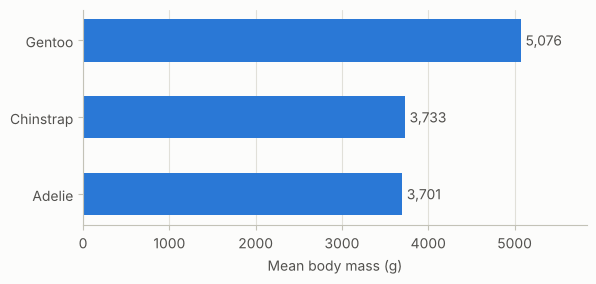

In [7]:
check_sorted_barh(sorted_barh)

`np.argsort(values)` gives the positions that would sort the values, so the labels can be reordered the same way and stay with their values. Sorting the two lists separately would detach each label from its bar, the classic "shuffled X and y separately" bug from Module 6, in chart form.

The x limit is set explicitly from 0, with 15% extra on the right so the value labels fit. A bar's length is its value, so a bar chart that doesn't start at zero misrepresents the data, as the lesson showed.

The value labels sit just past each bar's end, in a text colour rather than the bar colour, which keeps them readable. With exact values labelled, the vertical gridlines become optional. Here we turn off the horizontal gridlines, which serve no purpose on a horizontal bar chart.

The figure height grows with the number of bars, so a chart with 20 categories doesn't squash them into the same space as one with 3.

### Exercise 4: `save_figure`

In [8]:
from pathlib import Path


def save_figure(fig, path, formats=("png",)) -> list:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    saved = []
    for fmt in formats:
        target = path.with_suffix("." + fmt)
        fig.savefig(target, bbox_inches="tight")
        saved.append(target)
    plt.close(fig)
    return saved

In [9]:
check_save_figure(save_figure)

PASS  all 3 tests passed for save_figure


`path.with_suffix("." + fmt)` swaps in the extension for each format, and Matplotlib picks the file type from the extension.

`bbox_inches="tight"` crops the saved image to its content, so a long title or a legend outside the axes isn't cut off at the edge, which happens surprisingly often with the default.

Closing the figure matters when you generate many charts in a loop, say one per experiment or per class. Every open figure holds its data and drawing in memory, and Matplotlib starts warning once more than 20 are open. A save-and-close helper like this makes the right thing automatic.

PNG suits slides and quick sharing. SVG is a vector format: it stays sharp at any size and the text remains real text, which is better for documents and web pages.

## Medium

### Exercise 5: `scatter_by_group`

In [10]:
MARKER_SHAPES = ["o", "s", "^", "D", "v", "P", "X", "*"]


def scatter_by_group(df, x: str, y: str, group: str, order: list):
    fig, ax = plt.subplots()
    for i, name in enumerate(order):
        rows = df[df[group] == name]
        if rows.empty:
            continue
        ax.scatter(rows[x], rows[y], color=PALETTE[i], marker=MARKER_SHAPES[i], s=28,
                   edgecolors=SURFACE, linewidths=0.6, label=name)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.legend()
    return fig, ax

PASS  all 4 tests passed for scatter_by_group


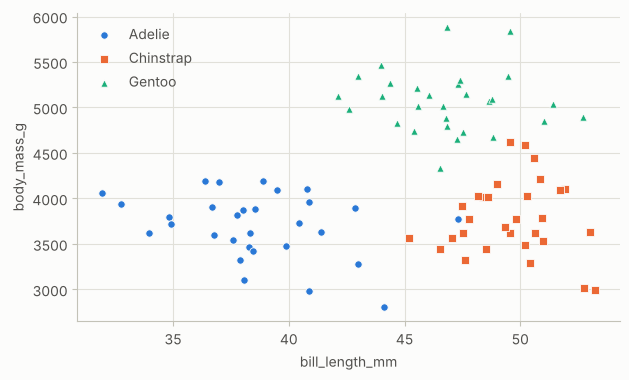

In [11]:
check_scatter_by_group(scatter_by_group)

The key line is `enumerate(order)`. Each group's colour comes from its position in the **full** list of groups, not from its position among the groups that happen to be in this particular DataFrame. So if a filter removes Adelie, Chinstrap stays orange instead of moving up to blue. That's the "colour follows the entity" rule from the lesson. Breaking it is a subtle way to mislead: a reader who learned "orange is Chinstrap" from one chart will misread the next.

The marker shapes are a second, independent way to tell the groups apart, for readers who can't distinguish some of the colours, and for black-and-white printing.

`edgecolors=SURFACE` gives every point a thin ring in the background colour, which keeps overlapping points distinguishable instead of merging into one blob.

### Exercise 6: `small_multiples`

In [12]:
def small_multiples(df, column: str, group: str, order: list, bins: int = 20):
    values = df[column].dropna()
    edges = np.linspace(values.min(), values.max(), bins + 1)

    fig, axes = plt.subplots(len(order), 1, figsize=(7, 1.8 * len(order)), sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for i, (ax, name) in enumerate(zip(axes, order)):
        group_values = df.loc[df[group] == name, column].dropna()
        ax.hist(group_values, bins=edges, color=PALETTE[i], edgecolor=SURFACE, linewidth=1)
        ax.text(0.99, 0.85, name, transform=ax.transAxes, ha="right", color=INK_2)
    axes[-1].set_xlabel(column)
    fig.tight_layout()
    return fig

PASS  all 4 tests passed for small_multiples


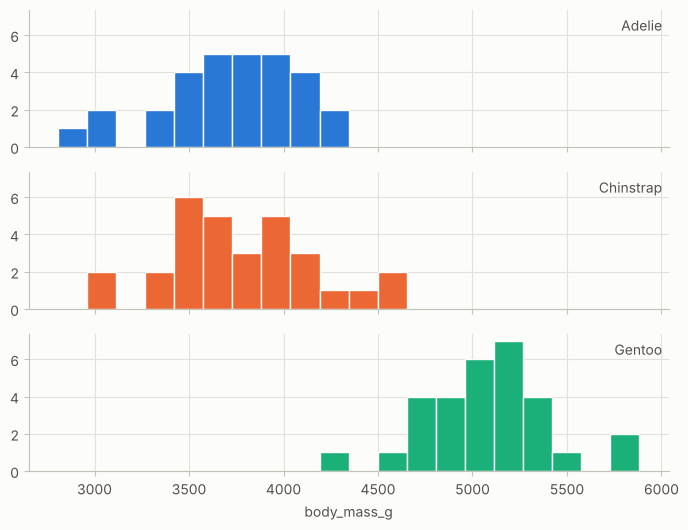

In [13]:
check_small_multiples(small_multiples)

**Shared bins** are the subtle part. If each panel called `hist(..., bins=20)`, each would compute its own 20 bins from its own minimum and maximum. The bars would have different widths and positions in each panel, and comparing them would be misleading. Computing `edges` once from the whole column, and passing those edges to every panel, makes the bars line up exactly.

**Shared axes** (`sharex=True, sharey=True`) put every panel on the same scale. Without `sharey`, a small group's tallest bar would fill its panel just like a big group's, hiding the difference in group sizes.

`np.atleast_1d(axes)` handles the case of a single group, where `plt.subplots(1, 1)` returns one `Axes` object rather than an array, which would break the `zip`.

Small multiples are often the best answer when overlapping several groups in one chart gets cluttered: the same chart, repeated, on the same scale.

### Exercise 7: `learning_curves`

In [14]:
def learning_curves(history):
    fig, ax = plt.subplots()
    ax.plot(history["epoch"], history["train_loss"], color=PALETTE[0], label="train")
    ax.plot(history["epoch"], history["val_loss"], color=PALETTE[1], label="validation")

    best = history.loc[history["val_loss"].idxmin()]
    ax.axvline(best["epoch"], color=MUTED, linewidth=1)
    ax.annotate(f"best: epoch {int(best['epoch'])}", xy=(best["epoch"], best["val_loss"]),
                xytext=(8, 12), textcoords="offset points", color=INK_2)

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    return fig, ax

PASS  all 3 tests passed for learning_curves


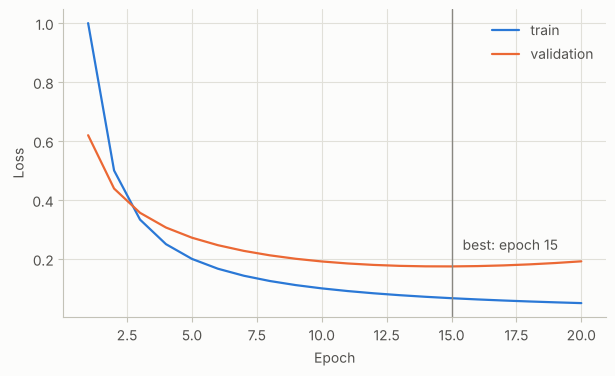

In [15]:
check_learning_curves(learning_curves)

`idxmin()` returns the index label of the smallest validation loss, and `.loc` fetches that whole row, giving both the epoch and the loss value for the annotation.

The vertical line is drawn in a muted grey. It's a reference, not data, so it shouldn't compete with the two curves. `annotate` with `textcoords="offset points"` places the label a fixed distance from the point, whatever the scale of the axes.

How to read the result: training loss keeps falling, because the model keeps fitting the training data better. Validation loss falls, bottoms out, then rises: past that point the model is fitting noise in the training data. The gap between the two curves is the overfitting. The marked epoch is where you'd stop, and it's the model early stopping would hand back.

### Exercise 8: `confusion_heatmap`

In [16]:
def confusion_heatmap(cm, labels: list):
    cm = np.asarray(cm)
    n = len(labels)
    fig, ax = plt.subplots(figsize=(1.1 * n + 2, 1.1 * n + 1.2))
    ax.imshow(cm, cmap=SEQUENTIAL)
    threshold = cm.max() / 2
    for i in range(n):
        for j in range(n):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > threshold else INK)
    ax.set_xticks(range(n), labels)
    ax.set_yticks(range(n), labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.grid(False)
    return fig, ax

PASS  all 4 tests passed for confusion_heatmap


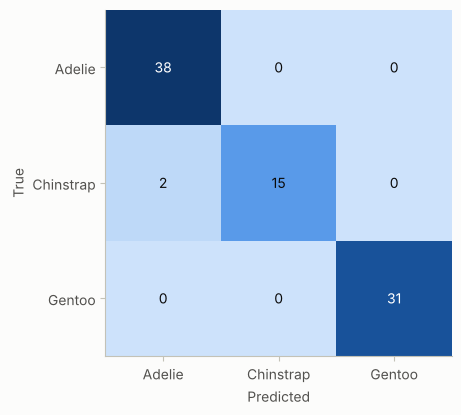

In [17]:
check_confusion_heatmap(confusion_heatmap)

`imshow` draws a 2D array as an image: row `i`, column `j` becomes the cell at `y = i`, `x = j`. That's why the text goes at `(j, i)`: the x coordinate is the column. Mixing those up puts each number in the mirrored cell, a bug that's easy to miss on a symmetric-looking matrix.

The two nested loops are fine here: they run once per *cell*, not once per data point, and a confusion matrix has a handful of cells.

Switching the text colour by cell darkness keeps every number readable. Dark text disappears on the darkest cells, and white text on the lightest. Using half the maximum count as the threshold is a simple rule that works well with a light-to-dark scale.

`ax.grid(False)` turns off the house-style gridlines, which would otherwise be drawn across the cells.

### Exercise 9: `indexed_chart`

In [18]:
def indexed_chart(df):
    indexed = df / df.iloc[0] * 100
    fig, ax = plt.subplots()
    ax.axhline(100, color=AXIS, linewidth=1)
    for i, column in enumerate(indexed.columns):
        ax.plot(indexed.index, indexed[column], color=PALETTE[i], marker="o", markersize=4,
                markeredgecolor=SURFACE, label=column)
    ax.set_ylabel("Index (first month = 100)")
    ax.legend()
    return fig, ax

PASS  all 3 tests passed for indexed_chart


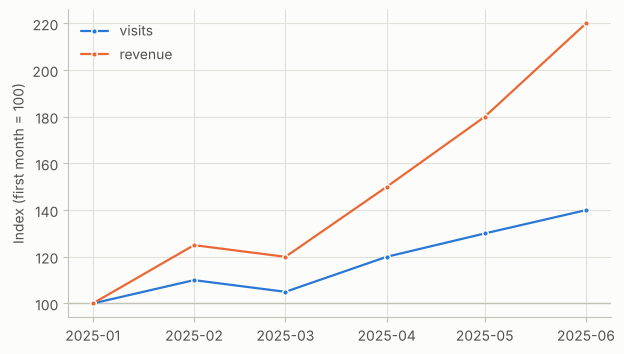

In [19]:
check_indexed_chart(indexed_chart)

`df / df.iloc[0]` divides every row by the first row. pandas lines the columns up by name, so each column is divided by its own starting value, in one operation.

After indexing, the y-axis means "relative to where we started", and both series share it honestly: 140 means 40% growth, whichever measure it is. Comparisons like "revenue grew faster than visits" become visible directly, without anyone choosing how to align two separate scales.

The reference line at 100 is drawn first, in the axis colour, so it sits behind the data. It marks "no change", which makes it easy to see at a glance which series grew and which shrank.

## Hard

### Exercise 10: `correlation_heatmap`

In [20]:
def correlation_heatmap(df):
    corr = df.corr()
    n = len(corr)
    fig, ax = plt.subplots(figsize=(1.2 * n + 2.5, 1.1 * n + 1.2))
    im = ax.imshow(corr.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1)
    for i in range(n):
        for j in range(n):
            value = corr.iat[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                    color="white" if abs(value) > 0.6 else INK)
    ax.set_xticks(range(n), corr.columns, rotation=30, ha="right")
    ax.set_yticks(range(n), corr.columns)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label="correlation")
    return fig, ax

PASS  all 2 tests passed for correlation_heatmap


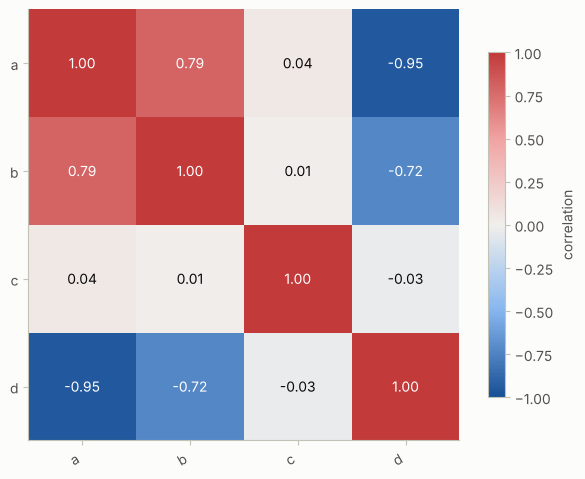

In [21]:
check_correlation_heatmap(correlation_heatmap)

**`vmin=-1, vmax=1` is the important part.** Without them, Matplotlib stretches the colour scale to the smallest and largest values actually present. In a dataset where every correlation is between 0.1 and 0.3, 0.3 would get the darkest red, a colour that should mean "almost perfectly related". Fixing the range means the colour always means the same thing.

The diverging scale fits because correlation has a meaningful midpoint, zero, with two opposite directions. Grey at zero reads as "nothing here", and blue and red read as opposite.

The text rule here uses the absolute value, since cells get dark at *both* ends of a diverging scale.

The diagonal is always 1.00, a column's correlation with itself. Some people hide the diagonal and the upper triangle (which mirrors the lower one) to reduce clutter. For a handful of columns, showing everything is usually clearer.

### Exercise 11: `decision_regions`

In [22]:
from matplotlib.colors import ListedColormap

MARKER_SHAPES = ["o", "s", "^", "D", "v", "P", "X", "*"]


def decision_regions(predict, X, y, labels: list, resolution: int = 200):
    X, y = np.asarray(X), np.asarray(y)
    k = len(labels)
    pad = 0.1 * (X.max(axis=0) - X.min(axis=0))
    lo, hi = X.min(axis=0) - pad, X.max(axis=0) + pad

    gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], resolution), np.linspace(lo[1], hi[1], resolution))
    grid = np.column_stack([gx.ravel(), gy.ravel()])
    regions = np.asarray(predict(grid)).reshape(gx.shape)

    fig, ax = plt.subplots()
    ax.contourf(gx, gy, regions, levels=np.arange(k + 1) - 0.5, cmap=ListedColormap(PALETTE[:k]), alpha=0.18)
    for c in range(k):
        pts = X[y == c]
        ax.scatter(pts[:, 0], pts[:, 1], color=PALETTE[c], marker=MARKER_SHAPES[c], s=26,
                   edgecolors=SURFACE, linewidths=0.6, label=labels[c])
    ax.set_xlim(lo[0], hi[0])
    ax.set_ylim(lo[1], hi[1])
    ax.grid(False)
    ax.legend()
    return fig, ax

PASS  all 3 tests passed for decision_regions


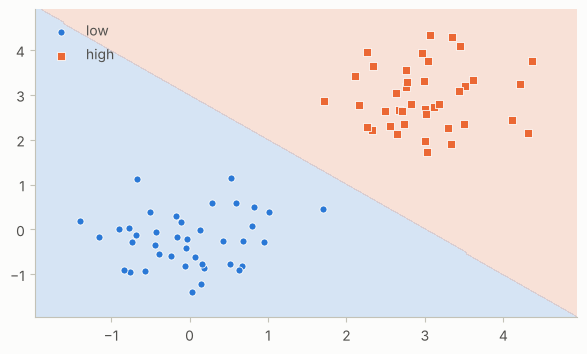

In [23]:
check_decision_regions(decision_regions)

**One prediction call.** `np.meshgrid` builds two `(resolution, resolution)` arrays of x and y coordinates. `ravel` flattens them and `column_stack` pairs them into `(resolution², 2)` points, a single batch for the model. Then `reshape` turns the predictions back into a grid. Calling `predict` once per point would mean 40,000 separate calls at the default resolution, which is painfully slow for any real model. The vectorized version is the Module 6 lesson, applied to plotting.

**`levels=np.arange(k + 1) - 0.5`** puts the contour boundaries halfway between class numbers (-0.5, 0.5, 1.5, ...), so each integer class gets exactly one colour band. With the default levels, `contourf` would invent its own boundaries and the colours wouldn't line up with the classes.

**`ListedColormap(PALETTE[:k])`** makes a colour map from exactly the palette colours, so region `k` and the points of class `k` share a colour, at a low `alpha` for the regions so the points stay prominent.

The padding matters more than it looks. Without it, points on the edge of the data sit right on the edge of the chart, and you can't see what the model does just beyond the data, which is often where models behave strangely.

### Exercise 12: `rolling_band`

In [24]:
import matplotlib.dates as mdates


def rolling_band(series, window: int):
    rolling = series.rolling(window, center=True)
    mean = rolling.mean()
    std = rolling.std()

    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(series.index, series.to_numpy(), color=PALETTE[0], alpha=0.3, linewidth=1, label="raw")
    ax.fill_between(series.index, (mean - std).to_numpy(), (mean + std).to_numpy(),
                    color=PALETTE[0], alpha=0.12, linewidth=0, label="± 1 std")
    ax.plot(series.index, mean.to_numpy(), color=PALETTE[0], linewidth=2, label=f"{window}-point mean")

    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    return fig, ax

PASS  all 3 tests passed for rolling_band


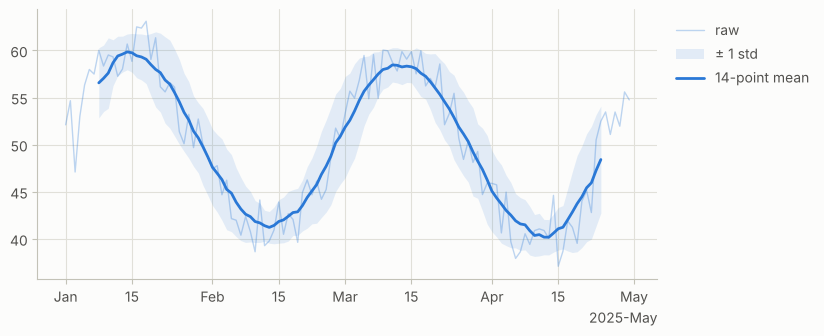

In [25]:
check_rolling_band(rolling_band)

`series.rolling(window, center=True)` creates the rolling window once, and both `.mean()` and `.std()` are computed from it. `center=True` lines each average up with the middle of its window. Without it, each value would be the average of the *previous* `window` points, so the smoothed line would lag behind the data, with every peak appearing late.

The first and last few values of a centred rolling mean are `NaN`, because there aren't enough points on one side. Matplotlib simply leaves gaps there rather than drawing anything misleading.

The drawing order matters: raw line, then band, then mean line on top, so the trend is never hidden. Using the same hue for all three, at different strengths (faint, wash, solid), shows they're all one series, and keeps the chart calm. Three different colours would suggest three different things.

Two layout details. With a few months of daily data, Matplotlib's default date labels (`2025-01-15`, `2025-02-01`, ...) are too long and run into each other. `ConciseDateFormatter` writes only what changes between ticks ("Jan", "Feb", with the year shown once), which fixes that. And the legend is placed just outside the plot with `bbox_to_anchor=(1.01, 1)`, because a wave like this fills every corner where a legend could otherwise go.

A band like this is not a confidence interval. It shows how much individual values vary around the trend, not how certain we are about the trend itself. Say which one a band is in the caption, because readers often assume the other.

## What's next

The mini project in `04_mini_project.ipynb` builds a one-page visual report on a penguin classifier: the data, the model's decisions, its learning curve and its mistakes.